<h1>Importing libraries</h1>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
from pathlib import Path

<h1>Import Monte-Carlo simulated head-to-head results</h1>

In [2]:
mc_head_to_head_results = pd.read_csv(
    f"{Path.cwd().parent}/data/processed/mc_head_to_head_results.csv", 
    dtype={
        'theta_p': np.float64,
        'theta_c': np.float64,
        's': 'Int64',
        'i': 'Int64',
        'P': 'Int64',
        'C': 'Int64',
        'm': 'Int64',
        't': 'Int64',
        'player_win': 'Int64'}
)

mc_head_to_head_results.head()

,theta_p,theta_c,s,i,P,C,m,t,player_win
0,0.3333,0.3333,-1,5,2,2,-6,2,0
1,0.3333,0.3333,-1,6,4,4,-4,7,0
2,0.3333,0.3333,-1,8,3,3,-5,3,0
3,0.3333,0.3333,-1,9,8,1,6,8,1
4,0.3333,0.3333,-1,10,3,3,-5,3,0


<h1>Calculating posterior probabilities</h1>
To get the joint distribution for $\theta_p$ and $f$, we want to calculate:
$$P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}) = \sum_{m, s} P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}|m=m_i, s=s_i)P(m=m_i, s=s_i)$$
<h2>$\theta_p$ and $f$</h2>
$$P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}|m=m_i, s=s_i)$$
<p>Given that a player $i$ wins (or loses) their head-to-head with margin $m$ after choosing a particular offer $s$, what's the probability that their accuracy is $\theta_p$ and the chaser's is $\theta_c = \theta_p + f$? We can use the  Monte-Carlo simulated head-to-head results to find this conditional probability.</p> 

In [3]:
# Count of each combination of theta_p, f, margin and s
joint = mc_head_to_head_results.groupby(["theta_p", "theta_c", "m", "s"]).size()

# Count of each combination of margin and s
evidence = mc_head_to_head_results.groupby(["m", "s"]).size()

# Posterior P(theta_p, f, margin, s | margin, s) = #(theta_p, f, margin, s) / #(margin, s)
posterior = (joint / evidence).rename("posterior_theta_p_theta_c").reset_index()
posterior = posterior[["m", "s", "theta_p", "theta_c", "posterior_theta_p_theta_c"]]
posterior = posterior.sort_values(by=["m", "s","theta_p", "theta_c"])
posterior.head()

,m,s,theta_p,theta_c,posterior_theta_p_theta_c
0,-6,-1,0.3333,0.3333,0.000372
1,-6,-1,0.3333,0.3433,0.000386
2,-6,-1,0.3333,0.3532,0.000438
3,-6,-1,0.3333,0.3632,0.000424
4,-6,-1,0.3333,0.3731,0.000461


<h2>Example</h2>

Consider you're a player, and you win the head-to-head by two spaces after choosing the middle offer. We can estimate a probability density function for your $\theta_p$ using our simulated head-to-head results.

In [4]:
m = 2
s = 0

example_posterior = posterior[(posterior['m']==m) & (posterior['s']==s)]
example_p = example_posterior.groupby("theta_p")["posterior_theta_p_theta_c"].sum().reset_index()

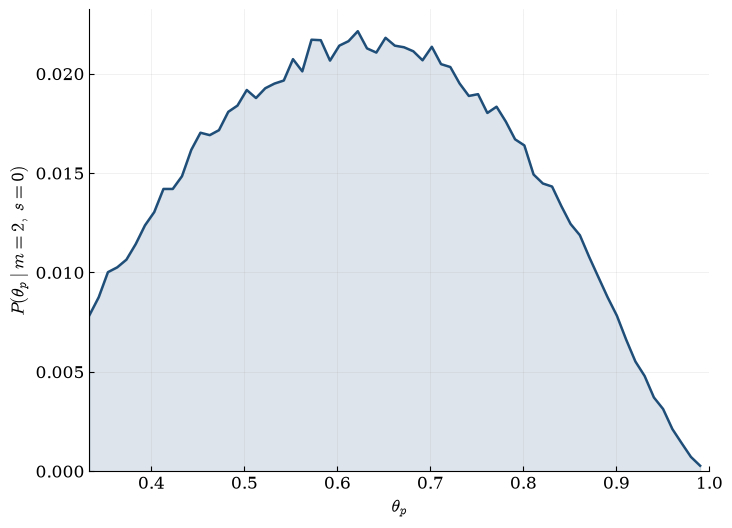

In [5]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",      
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

fig, ax = plt.subplots(figsize=(8, 6))   
ax.plot(example_p["theta_p"], example_p["posterior_theta_p_theta_c"], color="#1f4e79", lw=1.8)
ax.fill_between(example_p["theta_p"], example_p["posterior_theta_p_theta_c"], color="#1f4e79", alpha=0.15)

ax.set_xlabel(r"$\theta_p$")
ax.set_ylabel(r"$P(\theta_p \mid m=2,\, s=0)$")
ax.set_xlim(example_p["theta_p"].min(), 1)
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, lw=0.5)

# Save image in /figures
fig.savefig(f"{Path.cwd().parent}/figures/example_posterior.png", dpi=300)
plt.show()

<h1>Margin and offer choice</h1>

Now we'll work out the next part of the equation:
$$P(m=m_i, s=s_i)$$

<h3>Import player results</h3>

In [6]:
player_results = pd.read_csv(
    f"{Path.cwd().parent}/data/processed/player_results.csv"
)

player_results = player_results[['m', 's']]
player_results.head()

,m,s
0,4,0
1,3,1
2,-3,0
3,1,0
4,2,0


<h3>Find proportion of individual margins and choices</h3>

In [7]:
margin_and_choice = player_results.value_counts(normalize=True).rename('p_m_s').reset_index()
margin_and_choice = margin_and_choice.sort_values(['m', 's'], ignore_index = True)
margin_and_choice.head()

,m,s,p_m_s
0,-6,-1,0.011744
1,-5,-1,0.015129
2,-5,0,0.029729
3,-4,-1,0.012590
4,-4,0,0.057871


<h3>Combining the two probabilities</h3>

Now we can work out our joint distribution: $$P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}) = \sum_{m, s} P(\theta_p = \theta_{p,i}, \theta_c = \theta_{c,i}|m=m_i, s=s_i)P(m=m_i, s=s_i)$$

In [8]:
p_merged = margin_and_choice.merge(posterior, on=["m", "s"], how="left")
p_merged['p_theta_p_theta_c'] = p_merged['p_m_s'] * p_merged['posterior_theta_p_theta_c']
p_theta_p_theta_c = p_merged.groupby(["theta_p", 'theta_c'])["p_theta_p_theta_c"].sum().reset_index()
p_theta_p_theta_c.head()

,theta_p,theta_c,p_theta_p_theta_c
0,0.3333,0.3333,0.000130
1,0.3333,0.3433,0.000152
2,0.3333,0.3532,0.000167
3,0.3333,0.3632,0.000171
4,0.3333,0.3731,0.000157


<h2>Plotting the density</h2>

<h3>$\theta_p$</h3>

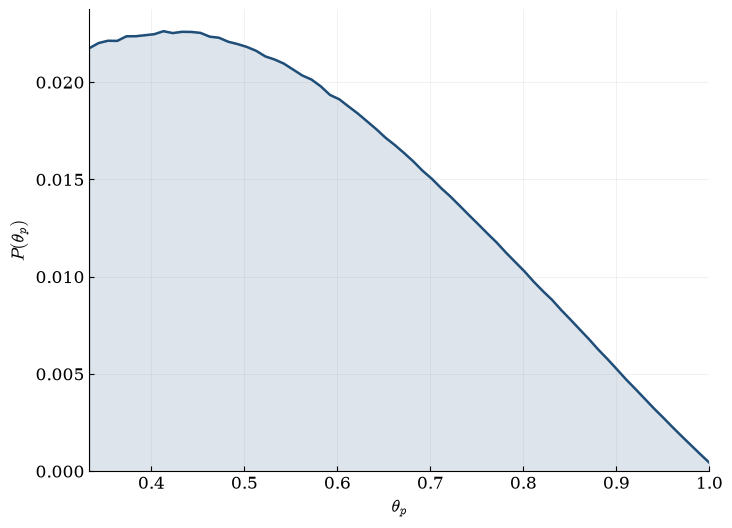

In [9]:
p_theta_p = p_theta_p_theta_c.groupby("theta_p")["p_theta_p_theta_c"].sum().reset_index()

fig, ax = plt.subplots(figsize=(8, 6))   # single-column journal width
ax.plot(p_theta_p["theta_p"], p_theta_p["p_theta_p_theta_c"], color="#1f4e79", lw=1.8)
ax.fill_between(p_theta_p["theta_p"], p_theta_p["p_theta_p_theta_c"], color="#1f4e79", alpha=0.15)

ax.set_xlabel(r"$\theta_p$")
ax.set_ylabel(r"$P(\theta_p)$")
ax.set_xlim(p_theta_p["theta_p"].min(), p_theta_p["theta_p"].max())
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, lw=0.5)

fig.savefig(f"{Path.cwd().parent}/figures/posterior_theta_p.png", dpi=300)
plt.show()

<h3>$E[\theta_p]$</h3>

In [10]:
sum(p_theta_p["theta_p"] * p_theta_p["p_theta_p_theta_c"])

0.5737850897910911

<h3>$\theta_c$</h3>

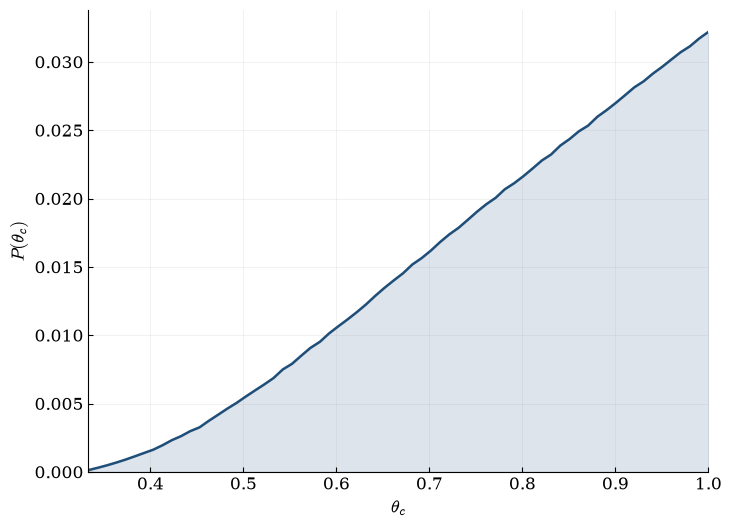

In [11]:
p_theta_c = p_theta_p_theta_c.groupby("theta_c")["p_theta_p_theta_c"].sum().reset_index()

fig, ax = plt.subplots(figsize=(8, 6))   # single-column journal width
ax.plot(p_theta_c ["theta_c"], p_theta_c ["p_theta_p_theta_c"], color="#1f4e79", lw=1.8)
ax.fill_between(p_theta_c ["theta_c"], p_theta_c ["p_theta_p_theta_c"], color="#1f4e79", alpha=0.15)

ax.set_xlabel(r"$\theta_c$")
ax.set_ylabel(r"$P(\theta_c)$")
ax.set_xlim(p_theta_c["theta_c"].min(), p_theta_c["theta_c"].max())
ax.set_ylim(bottom=0)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, lw=0.5)

fig.savefig(f"{Path.cwd().parent}/figures/posterior_theta_c.png", dpi=300)
plt.show()

<h3>$E[\theta_c]$</h3>

In [12]:
sum(p_theta_c["theta_c"] * p_theta_c["p_theta_p_theta_c"])

0.7993846020810697